KleinGPT

A tiny GPT trained on TinyStories. CPU/GPU-friendly, no MLflow.

In [35]:
import os
import math
import random
import time
from itertools import islice

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from datasets import load_dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


In [36]:
# Dataset sample sizes
TRAIN_STORIES = 5_000
VAL_STORIES   = 500

# Model and training settings
BLOCK_SIZE    = 128
BATCH_SIZE    = 12
MAX_ITERS     = 300
EVAL_INTERVAL = 50
EVAL_BATCHES  = 10
LEARNING_RATE = 3e-4
WEIGHT_DECAY  = 1e-4
N_EMBD        = 128
N_HEAD        = 4
N_LAYER       = 2
DROPOUT       = 0.0

In [37]:
train_stream = load_dataset("roneneldan/TinyStories", split="train", streaming=True)
val_stream   = load_dataset("roneneldan/TinyStories", split="validation", streaming=True)

train_examples = list(islice(train_stream, TRAIN_STORIES))
val_examples   = list(islice(val_stream, VAL_STORIES))

train_text = "\n".join(ex["text"] for ex in train_examples)
val_text   = "\n".join(ex["text"] for ex in val_examples)

print(f"Training stories:   {len(train_examples):,}")
print(f"Validation stories: {len(val_examples):,}")
print(f"Training characters:   {len(train_text):,}")
print(f"Validation characters: {len(val_text):,}")

Training stories:   5,000
Validation stories: 500
Training characters:   4,181,739
Validation characters: 405,580


In [38]:
#tokenizing the datasets...
vocab = sorted(set(train_text))
vocab_size = len(vocab)

stoi = {ch: i for i, ch in enumerate(vocab)}
itos = {i: ch for i, ch in enumerate(vocab)}

def encode(text):
    return [stoi[ch] for ch in text if ch in stoi]

def decode(token_ids):
    return "".join(itos[int(i)] for i in token_ids)

print("Vocabulary size:", vocab_size)

Vocabulary size: 90


In [39]:
#converting all the texts into pytorch tensors
train_ids = torch.tensor(encode(train_text), dtype=torch.long)
val_ids   = torch.tensor(encode(val_text), dtype=torch.long)

print("Training tokens:", f"{len(train_ids):,}")
print("Validation tokens:", f"{len(val_ids):,}")

if len(train_ids) <= BLOCK_SIZE or len(val_ids) <= BLOCK_SIZE:
    raise ValueError("Not enough encoded text for BLOCK_SIZE.")

Training tokens: 4,181,739
Validation tokens: 405,580


In [40]:
def get_batch(split):
    data = train_ids if split == "train" else val_ids
    ix = torch.randint(len(data) - BLOCK_SIZE - 1, (BATCH_SIZE,))
    x = torch.stack([data[i : i + BLOCK_SIZE] for i in ix])
    y = torch.stack([data[i + 1 : i + BLOCK_SIZE + 1] for i in ix])
    return x.to(DEVICE), y.to(DEVICE)

In [41]:
class CausalSelfAttention(nn.Module):
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        assert n_embd % n_head == 0
        self.n_head = n_head
        self.head_dim = n_embd // n_head
        self.qkv = nn.Linear(n_embd, 3 * n_embd, bias=False)
        self.proj = nn.Linear(n_embd, n_embd)
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)
        self.register_buffer(
            "causal_mask",
            torch.tril(torch.ones(block_size, block_size))
                 .view(1, 1, block_size, block_size),
        )

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        q = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_head, self.head_dim).transpose(1, 2)

        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)
        scores = scores.masked_fill(self.causal_mask[:, :, :T, :T] == 0, float("-inf"))
        weights = F.softmax(scores, dim=-1)
        weights = self.attn_dropout(weights)

        out = weights @ v
        out = out.transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_dropout(self.proj(out))


class FeedForward(nn.Module):
    def __init__(self, n_embd, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.GELU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(n_embd)
        self.attn = CausalSelfAttention(n_embd, n_head, block_size, dropout)
        self.ln2 = nn.LayerNorm(n_embd)
        self.ffwd = FeedForward(n_embd, dropout)

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x


class TinyGPT(nn.Module):
    def __init__(self, vocab_size, block_size, n_embd, n_head, n_layer, dropout):
        super().__init__()
        self.block_size = block_size
        self.token_embedding = nn.Embedding(vocab_size, n_embd)
        self.position_embedding = nn.Embedding(block_size, n_embd)
        self.dropout = nn.Dropout(dropout)
        self.blocks = nn.Sequential(*[
            TransformerBlock(n_embd, n_head, block_size, dropout)
            for _ in range(n_layer)
        ])
        self.final_norm = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size, bias=False)
        self.lm_head.weight = self.token_embedding.weight  # weight tying
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        if T > self.block_size:
            raise ValueError(f"Sequence length {T} exceeds block size {self.block_size}")
        positions = torch.arange(T, device=idx.device)
        x = self.token_embedding(idx) + self.position_embedding(positions)
        x = self.dropout(x)
        x = self.blocks(x)
        x = self.final_norm(x)
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            B, T, C = logits.shape
            loss = F.cross_entropy(logits.view(B * T, C), targets.view(B * T))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.block_size:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / max(temperature, 1e-5)
            if top_k is not None:
                values, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < values[:, [-1]]] = float("-inf")
            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, next_id), dim=1)
        self.train()
        return idx


model = TinyGPT(
    vocab_size=vocab_size,
    block_size=BLOCK_SIZE,
    n_embd=N_EMBD,
    n_head=N_HEAD,
    n_layer=N_LAYER,
    dropout=DROPOUT,
).to(DEVICE)

num_params = sum(p.numel() for p in model.parameters())
print(f"Model parameters: {num_params:,}")
print(f"Approx. parameter memory (float32): {num_params * 4 / 1e6:.2f} MB")

Model parameters: 423,936
Approx. parameter memory (float32): 1.70 MB


In [42]:
xb, yb = get_batch("train")
logits, initial_loss = model(xb, yb)
print("Logits shape:", tuple(logits.shape))
print("Initial loss:", round(initial_loss.item(), 4))
print("Expected loss ≈", round(math.log(vocab_size), 4), "(random baseline)")

Logits shape: (12, 128, 90)
Initial loss: 4.5144
Expected loss ≈ 4.4998 (random baseline)


In [43]:
@torch.no_grad()
def estimate_loss():
    model.eval()
    results = {}
    for split in ("train", "val"):
        losses = torch.zeros(EVAL_BATCHES)
        for k in range(EVAL_BATCHES):
            X, Y = get_batch(split)
            _, loss = model(X, Y)
            losses[k] = loss.item()
        results[split] = losses.mean().item()
    model.train()
    return results


optimizer = torch.optim.AdamW(
    model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
)

train_history, val_history, step_history = [], [], []
start_time = time.time()

for step in range(MAX_ITERS):
    if step % EVAL_INTERVAL == 0 or step == MAX_ITERS - 1:
        losses = estimate_loss()
        train_history.append(losses["train"])
        val_history.append(losses["val"])
        step_history.append(step)
        elapsed = time.time() - start_time
        print(
            f"step {step:4d} | "
            f"train {losses['train']:.4f} | "
            f"val {losses['val']:.4f} | "
            f"{elapsed/60:.2f} min"
        )

    X, Y = get_batch("train")
    _, loss = model(X, Y)

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()

total_training_time = time.time() - start_time
print(f"\nTraining finished in {total_training_time/60:.2f} minutes.")

step    0 | train 4.5204 | val 4.5153 | 0.00 min
step   50 | train 2.7849 | val 2.7551 | 0.01 min
step  100 | train 2.5107 | val 2.4861 | 0.02 min
step  150 | train 2.4077 | val 2.4074 | 0.03 min
step  200 | train 2.3665 | val 2.3667 | 0.03 min
step  250 | train 2.3163 | val 2.3144 | 0.04 min
step  299 | train 2.2954 | val 2.3101 | 0.05 min

Training finished in 0.05 minutes.


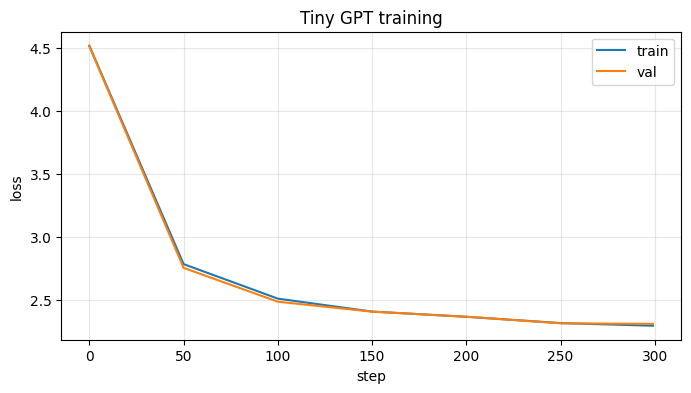

In [44]:
plt.figure(figsize=(8, 4))
plt.plot(step_history, train_history, label="train")
plt.plot(step_history, val_history, label="val")
plt.xlabel("step")
plt.ylabel("loss")
plt.legend()
plt.title("Tiny GPT training")
plt.grid(True, alpha=0.3)
plt.show()

In [45]:
prompt = "Once upon a time"
context = torch.tensor([encode(prompt)], dtype=torch.long, device=DEVICE)

out = model.generate(context, max_new_tokens=200, temperature=0.8, top_k=40)
print(decode(out[0].tolist()))

Once upon a timed, lewandeÃ hee we d feato ds masoule buthe ane, r angthow this oucog nthe.


Tolor tes genen hl. kere pe, the wan ""Thatthe vened andte casome s lowalichand her d ad thie be s hale ove nge anletiom a


In [46]:
os.makedirs("checkpoints", exist_ok=True)
torch.save({
    "model_state_dict": model.state_dict(),
    "vocab": vocab,
    "config": {
        "block_size": BLOCK_SIZE,
        "n_embd": N_EMBD,
        "n_head": N_HEAD,
        "n_layer": N_LAYER,
        "dropout": DROPOUT,
        "vocab_size": vocab_size,
    },
}, "checkpoints/tiny_gpt.pt")
print("Saved to checkpoints/tiny_gpt.pt")

Saved to checkpoints/tiny_gpt.pt
